In [6]:
import xarray as xr 
import numpy as np
from glob import glob
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib import cm
import matplotlib.pyplot as plt

from cmcrameri import cm as cmcra
import plotting_utils

In [16]:
# importing processed dataset
path_source = Path('../steady_out/') 
exp = 'TEMP'
ds_steady = xr.open_dataset(str(path_source / (exp + '.nc')))

path_source = Path('../monthly_out/') 
exp =  'TEMP_m'
ds_monthly = xr.open_dataset(str(path_source / (exp + '.nc')))

In [17]:
# define lists

time_list = np.linspace(0,160,160*12) # years

T0_list = [2,1,0,-1,-1.9] # °C

sfx_list = np.arange(0, 0.075+0.001, 0.005) # g/m^2/s

labels = ['2 °C', '1 °C', '0 °C', '-1 °C', '-1.9 °C']

colors_plot =  [cm.coolwarm(x) for x in np.linspace(1, 0, 4)]+[cmcra.lipari(0.05)]

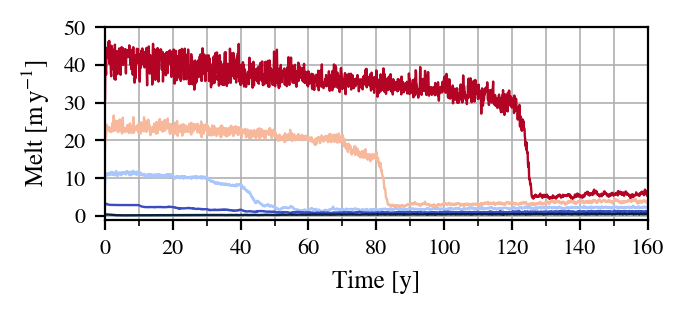

In [18]:
# warm-to-cold monthly

plt.figure(figsize=(16/16*3.5,1.25),dpi=200)

for index, T0 in enumerate(T0_list):

    melt = ds_monthly.melt.sel(transition="wtc", T0=T0).isel(time=slice(0,160*12)).values

    plt.plot(time_list, melt, color=colors_plot[index], label=labels[index], linewidth=0.85)

plt.xlabel(r'Time [y]') 
plt.ylabel(r'Melt [$\mathrm{m \, \mathrm{y}^{-1}}$]')


plt.xlim(0,160)

ax = plt.gca()

from matplotlib.ticker import MultipleLocator
ax.xaxis.set_major_locator(MultipleLocator(20)) # Major ticks → every 20 (these get labels)
ax.xaxis.set_minor_locator(MultipleLocator(10)) # Minor ticks → every 10 (grid only)

ax.set_yticks(np.arange(0,50+1,10))

plt.ylim(-1,50)


ax.grid(which='major', lw=0.6)
ax.grid(which='minor', lw=0.6)

plt.savefig('./Figure4/monthly_melt_wtc.pdf', format='pdf', bbox_inches='tight')
plt.show()

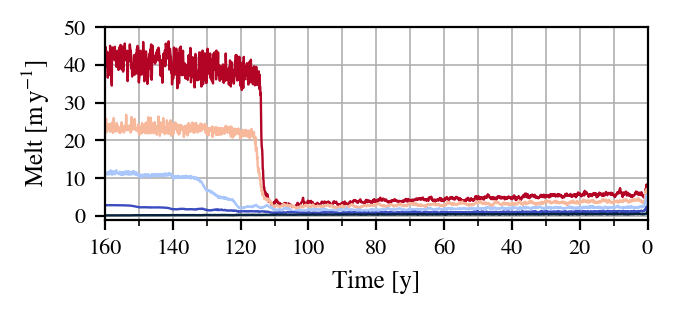

In [19]:
# cold-to-warm monthly

plt.figure(figsize=(16/16*3.5,1.25),dpi=200)

for index, T0 in enumerate(T0_list):

    melt = ds_monthly.melt.sel(transition="ctw", T0=T0).isel(time=slice(0,160*12)).values

    plt.plot(time_list, melt, color=colors_plot[index], label=labels[index], linewidth=0.85)

plt.xlabel(r'Time [y]') 
plt.ylabel(r'Melt [$\mathrm{m \, \mathrm{y}^{-1}}$]')


plt.xlim(0,160)

ax = plt.gca()

from matplotlib.ticker import MultipleLocator
ax.xaxis.set_major_locator(MultipleLocator(20)) # Major ticks → every 20 (these get labels)
ax.xaxis.set_minor_locator(MultipleLocator(10)) # Minor ticks → every 10 (grid only)

ax.set_yticks(np.arange(0,50+1,10))

ax.invert_xaxis()

plt.ylim(-1,50)


ax.grid(which='major', lw=0.6)
ax.grid(which='minor', lw=0.6)

plt.savefig('./Figure4/monthly_melt_ctw.pdf', format='pdf', bbox_inches='tight')
plt.show()

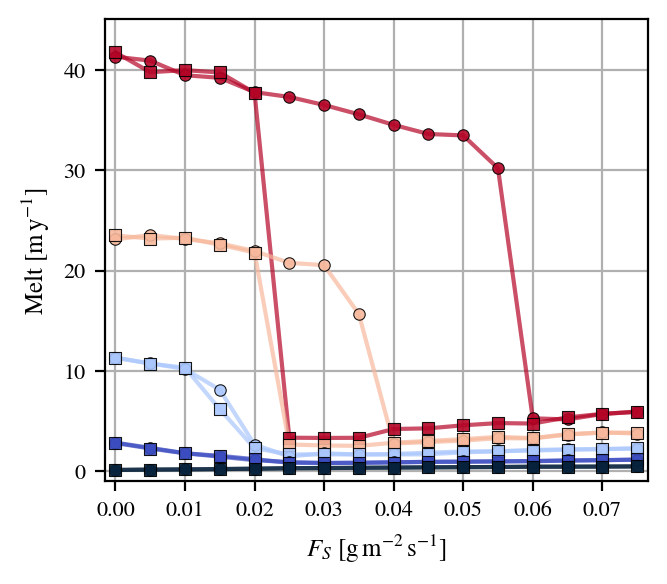

In [20]:
# Hysteresis

plt.figure(figsize=(3.5,3),dpi=200)

for index, T0 in enumerate(T0_list):

    melt_wtc = ds_steady.melt_0D.sel(transition="wtc", T0=T0).values[:16]
    melt_ctw = ds_steady.melt_0D.sel(transition="ctw", T0=T0).values[:16]
    
    plt.plot(sfx_list, melt_wtc, color=colors_plot[index], alpha=0.7,)
    plt.plot(sfx_list, melt_ctw, color=colors_plot[index], alpha=0.7,)


for index, T0 in enumerate(T0_list):

    melt_wtc = ds_steady.melt_0D.sel(transition="wtc", T0=T0).values[:16]
    melt_ctw = ds_steady.melt_0D.sel(transition="ctw", T0=T0).values[:16]

    plt.scatter(sfx_list, melt_wtc, marker='o', edgecolors='black', facecolors=colors_plot[index], lw=0.4, s=17, alpha=0.9,zorder=2, label=labels[index])
    plt.scatter(sfx_list, melt_ctw, marker='s', edgecolors='black', facecolors=colors_plot[index], lw=0.4, s=17, alpha=0.9,zorder=2)

plt.xlabel(r'$F_S$ [$\mathrm{g \, m^{-2} \, s^{-1}}$]') 
plt.ylabel(r'Melt [$\mathrm{m \, \mathrm{y}^{-1}}$]')


plt.xlim(0-0.0015,0.075+0.0015)
plt.ylim(-1, 45)

#plt.yscale('log')

plt.grid()

plt.savefig('./Figure4/hyst_melt.pdf', format='pdf', bbox_inches='tight')

plt.show()